# 1. Importing libraries and setup

In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path("../data/processed")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")

MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("ARIMA & SARIMA Environment Ready!")

ARIMA & SARIMA Environment Ready!


# 2. Load Daily Time Series
We'll load the cleaned time series again and verify its date range before splitting the data

In [3]:
CALENDAR_PATH = DATA_DIR / "calendar_cleaned.csv"
SALES_PATH = Path("../data/raw/m5/sales_train_validation.csv")

calendar = pd.read_csv(CALENDAR_PATH, parse_dates=["date"])

sales_header = pd.read_csv(SALES_PATH, nrows=0)
daily_columns = [col for col in sales_header.columns if col.startswith("d_")]

daily_sales = pd.Series(0, index=daily_columns, dtype="int64")

for chunk in pd.read_csv(SALES_PATH, chunksize=500):
    daily_sales = daily_sales.add(
        chunk[daily_columns].sum(),
        fill_value=0
    )

daily_ts = pd.DataFrame({
    "date": calendar.set_index("d").loc[daily_columns, "date"].values,
    "sales": daily_sales.values
})

daily_ts = daily_ts.set_index("date").sort_index()
daily_ts.index = pd.DatetimeIndex(daily_ts.index)

print("Time Series Shape:", daily_ts.shape)
print("Date Range:", daily_ts.index.min(), "to", daily_ts.index.max())
print("Missing Values:", daily_ts["sales"].isna().sum())

display(daily_ts.head())
display(daily_ts.tail())

Time Series Shape: (1913, 1)
Date Range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Missing Values: 0


,sales
date,
2011-01-29,32631
2011-01-30,31749
2011-01-31,23783
2011-02-01,25412
2011-02-02,19146


,sales
date,
2016-04-20,35343
2016-04-21,35033
2016-04-22,40517
2016-04-23,48962
2016-04-24,49795


# 3. Train-Test Split
We'll use the last 90 days as test data and the remaining observations for training.

Why?
- Training data helps the model learn historical patterns.
- Test data checks how accurately it forecasts unseen dates.
- A 90-day test period matches our project's demand forecasting goal.

In [4]:
test_size = 90

train = daily_ts["sales"].iloc[:-test_size]
test = daily_ts["sales"].iloc[-test_size:]

print("Training Observations:", len(train))
print("Testing Observations:", len(test))

print("\nTraining Period:", train.index.min(), "to", train.index.max())
print("Testing Period:", test.index.min(), "to", test.index.max())

print("\nTraining Mean Sales:", round(train.mean(), 2))
print("Testing Mean Sales:", round(test.mean(), 2))

Training Observations: 1823
Testing Observations: 90

Training Period: 2011-01-29 00:00:00 to 2016-01-25 00:00:00
Testing Period: 2016-01-26 00:00:00 to 2016-04-24 00:00:00

Training Mean Sales: 33970.5
Testing Mean Sales: 41857.73


One important observation: test mean sales (41,857.73) is higher than training mean sales (33,970.50). This suggests the upward demand trend may make forecasting more challenging.

# 4. Seasonal Naive Baseline
Before ARIMA/SARIMA, we'll create a baseline model.

Since our data has weekly seasonality, the model will assume:

Today's forecast = Sales on the same weekday last week.

In [5]:
seasonal_period = 7

baseline_forecast = train.iloc[-seasonal_period:].values

baseline_forecast = np.tile(
    baseline_forecast,
    int(np.ceil(len(test) / seasonal_period))
)[:len(test)]

baseline_forecast = pd.Series(
    baseline_forecast,
    index=test.index
)

print("Baseline Forecast Shape:", baseline_forecast.shape)
print("\nFirst 10 Forecast Values:")
display(baseline_forecast.head(10))

Baseline Forecast Shape: (90,)

First 10 Forecast Values:


date
2016-01-26    31988
2016-01-27    32684
2016-01-28    31779
2016-01-29    36307
2016-01-30    48927
2016-01-31    47832
2016-02-01    34389
2016-02-02    31988
2016-02-03    32684
2016-02-04    31779
dtype: int64

# 5. Evaluate Baseline Model
Now let's calculate its forecasting errors. We'll use:
- MAE: Average absolute prediction error.
- RMSE: Penalizes larger errors more heavily.
- WMAPE: Total absolute error relative to actual demand.

In [6]:
baseline_mae = mean_absolute_error(test, baseline_forecast)

baseline_rmse = np.sqrt(
    mean_squared_error(test, baseline_forecast)
)

baseline_wmape = (
    np.sum(np.abs(test - baseline_forecast)) /
    np.sum(test)
) * 100

print("Seasonal Naive Baseline Performance")
print("------------------------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("WMAPE:", round(baseline_wmape, 2), "%")

Seasonal Naive Baseline Performance
------------------------------------
MAE: 4341.66
RMSE: 5117.31
WMAPE: 10.37 %


Interpretation: The baseline has a WMAPE of 10.37%, meaning its total absolute forecasting error is about 10.37% of actual demand over the test period.

# 6. Visualize Actual vs Baseline Forecast

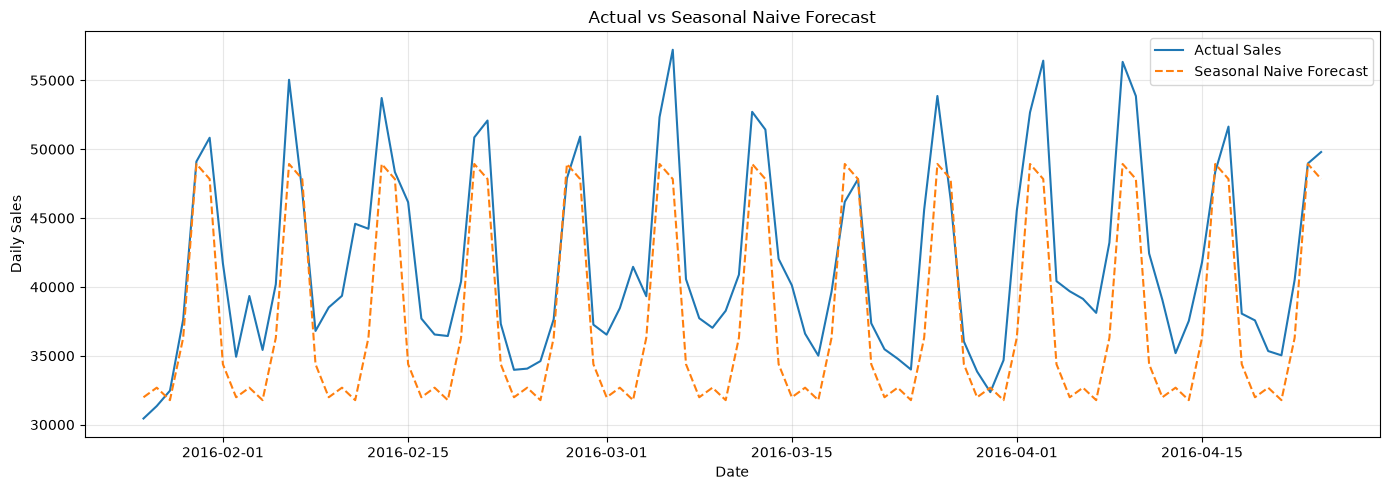

In [7]:
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Actual Sales")
plt.plot(
    baseline_forecast.index,
    baseline_forecast,
    label="Seasonal Naive Forecast",
    linestyle="--"
)

plt.title("Actual vs Seasonal Naive Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Fit ARIMA Model
We'll start with ARIMA(1,1,1).
- p = 1: One autoregressive term.
- d = 1: First-order differencing.
- q = 1: One moving-average term.
We'll fit it only on training data to avoid data leakage.

In [8]:
arima_model = ARIMA(
    train,
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                 1823
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -18174.831
Date:                Thu, 12 Nov 2026   AIC                          36355.662
Time:                        09:41:59   BIC                          36372.185
Sample:                    01-29-2011   HQIC                         36361.757
                         - 01-25-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4954      0.023     21.692      0.000       0.451       0.540
ma.L1         -0.9825      0.007   -150.517      0.000      -0.995      -0.970
sigma2      3.332e+07   1.02e-10   3.26e+17      0.0

1. Both AR and MA coefficients are statistically significant (p-value below 0.05).
2. The MA coefficient is close to -1.
3. Ljung–Box p-value is 0.00, indicating residual autocorrelation remains.
4. Jarque–Bera p-value is 0.00, indicating residuals are not normally distributed.
5. The covariance matrix warning suggests some coefficient uncertainty; we'll keep this in mind.
ARIMA has fitted successfully, but we cannot judge its forecasting performance from this summary alone.

# 8. Generate ARIMA Forecast
Now let's forecast the next 90 days and compare it with our actual test data.

In [9]:
arima_forecast_result = arima_result.get_forecast(
    steps=len(test)
)

arima_forecast = arima_forecast_result.predicted_mean

arima_conf_int = arima_forecast_result.conf_int()

print("ARIMA Forecast Shape:", arima_forecast.shape)

print("\nFirst 10 Forecast Values:")
display(arima_forecast.head(10))

print("\nConfidence Intervals:")
display(arima_conf_int.head(10))

ARIMA Forecast Shape: (90,)

First 10 Forecast Values:


2016-01-26    36219.555847
2016-01-27    37126.391355
2016-01-28    37575.626838
2016-01-29    37798.172732
2016-01-30    37908.419311
2016-01-31    37963.034150
2016-02-01    37990.089688
2016-02-02    38003.492679
2016-02-03    38010.132361
2016-02-04    38013.421580
Freq: D, Name: predicted_mean, dtype: float64


Confidence Intervals:


,lower sales,upper sales
2016-01-26,24906.175617,47532.936076
2016-01-27,24411.550911,49841.231800
2016-01-28,24494.659728,50656.593949
2016-01-29,24604.493484,50991.851980
2016-01-30,24672.947034,51143.891588
2016-01-31,24708.040919,51218.027380
2016-02-01,24723.494611,51256.684765
2016-02-02,24728.458859,51278.526500
2016-02-03,24728.041408,51292.223314
2016-02-04,24724.913339,51301.929821


# 9. Evaluate ARIMA Performance
Now let's compare ARIMA against our seasonal-naive baseline using the same metrics.

In [10]:
arima_mae = mean_absolute_error(test, arima_forecast)

arima_rmse = np.sqrt(
    mean_squared_error(test, arima_forecast)
)

arima_wmape = (
    np.sum(np.abs(test - arima_forecast)) /
    np.sum(test)
) * 100

print("ARIMA(1,1,1) Performance")
print("------------------------")
print("MAE:", round(arima_mae, 2))
print("RMSE:", round(arima_rmse, 2))
print("WMAPE:", round(arima_wmape, 2), "%")

ARIMA(1,1,1) Performance
------------------------
MAE: 5712.29
RMSE: 7816.71
WMAPE: 13.65 %


### ARIMA(1,1,1) Model Evaluation

1. ARIMA achieved a WMAPE of 13.65%.
2. The seasonal-naive baseline achieved a lower WMAPE of 10.37%.
3. ARIMA also produced higher MAE and RMSE values.
4. The model does not explicitly account for weekly seasonality.

Conclusion: ARIMA(1,1,1) did not outperform the seasonal-naive baseline. A seasonal ARIMA model will be explored to capture weekly demand patterns.

# Visualize ARIMA Forecast

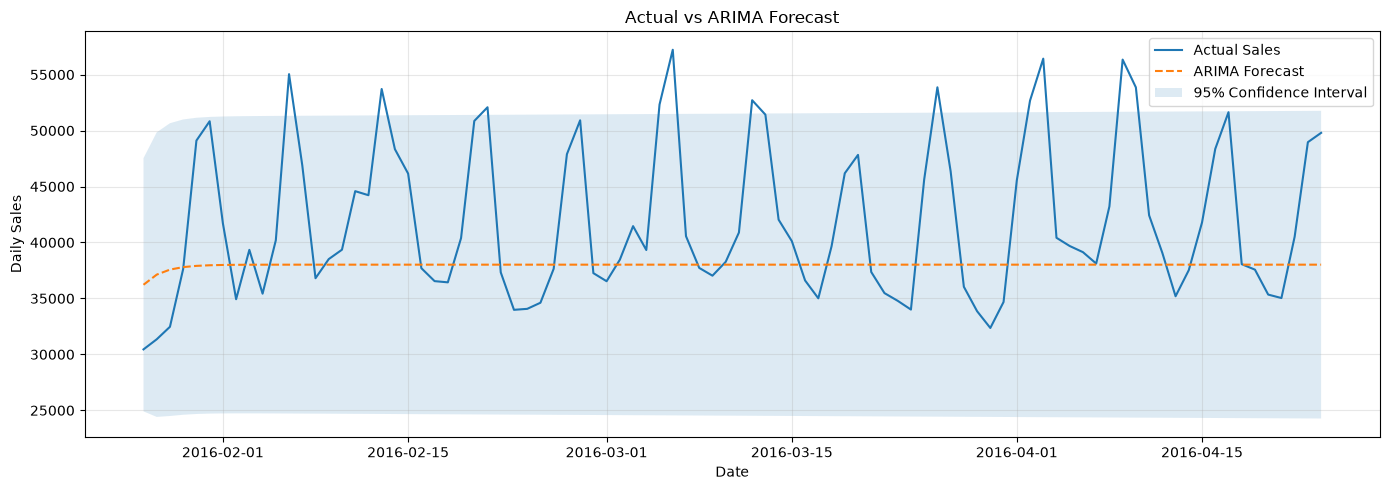

In [11]:
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Actual Sales")
plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast",
    linestyle="--"
)

plt.fill_between(
    test.index,
    arima_conf_int.iloc[:, 0],
    arima_conf_int.iloc[:, 1],
    alpha=0.15,
    label="95% Confidence Interval"
)

plt.title("Actual vs ARIMA Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 10. Fit SARIMA Model
We'll start with:

SARIMA(1,1,1)(1,1,1,7)
- Non-seasonal order: (1,1,1)
- Seasonal order: (1,1,1,7)
- 7 represents the weekly seasonal cycle.

In [12]:
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)

print(sarima_result.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             sales   No. Observations:                 1823
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood              -17309.368
Date:                           Thu, 12 Nov 2026   AIC                          34628.737
Time:                                   09:43:33   BIC                          34656.231
Sample:                               01-29-2011   HQIC                         34638.884
                                    - 01-25-2016                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3977      0.022     17.781      0.000       0.354       0.442
ma.L1         -0.9653      0.014    -70.136

# 11. Generate SARIMA Forecast

In [13]:
sarima_forecast_result = sarima_result.get_forecast(
    steps=len(test)
)

sarima_forecast = sarima_forecast_result.predicted_mean

sarima_conf_int = sarima_forecast_result.conf_int()

print("SARIMA Forecast Shape:", sarima_forecast.shape)

print("\nFirst 10 Forecast Values:")
display(sarima_forecast.head(10))

print("\nConfidence Intervals:")
display(sarima_conf_int.head(10))

SARIMA Forecast Shape: (90,)

First 10 Forecast Values:


2016-01-26    32833.443834
2016-01-27    33194.853894
2016-01-28    33931.947227
2016-01-29    35253.708617
2016-01-30    46051.387966
2016-01-31    45695.990702
2016-02-01    35826.571357
2016-02-02    33627.267166
2016-02-03    33512.399897
2016-02-04    34234.436042
Freq: D, Name: predicted_mean, dtype: float64


Confidence Intervals:


,lower sales,upper sales
2016-01-26,24268.320752,41398.566915
2016-01-27,23863.088070,42526.619718
2016-01-28,24433.652508,43430.241946
2016-01-29,25702.720318,44804.696916
2016-01-30,36475.068599,55627.707333
2016-01-31,36102.457618,55289.523786
2016-02-01,26218.625417,45434.517297
2016-02-02,23805.045533,43449.488799
2016-02-03,23621.634386,43403.165408
2016-02-04,24310.296726,44158.575357


One good sign: unlike basic ARIMA, SARIMA is capturing the weekly pattern in its predictions. Notice how Saturday and Sunday forecasts are higher.

The confidence intervals are also available for uncertainty analysis.

# 12. Evaluate SARIMA Performance

In [14]:
sarima_mae = mean_absolute_error(test, sarima_forecast)

sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_forecast)
)

sarima_wmape = (
    np.sum(np.abs(test - sarima_forecast)) /
    np.sum(test)
) * 100

print("SARIMA(1,1,1)(1,1,1,7) Performance")
print("-----------------------------------")
print("MAE:", round(sarima_mae, 2))
print("RMSE:", round(sarima_rmse, 2))
print("WMAPE:", round(sarima_wmape, 2), "%")

SARIMA(1,1,1)(1,1,1,7) Performance
-----------------------------------
MAE: 4450.62
RMSE: 5361.63
WMAPE: 10.63 %


### SARIMA Model Evaluation

1. SARIMA achieved a WMAPE of 10.63%, performing better than ARIMA (13.65%).
2. The seasonal-naive baseline achieved the lowest WMAPE of 10.37%.
3. SARIMA also produced lower MAE and RMSE than ARIMA.
4. Although SARIMA captured weekly seasonality, it did not outperform the baseline.

Conclusion: SARIMA is a significant improvement over ARIMA, but the seasonal-naive model remains the strongest benchmark so far.

# 12. SARIMA Residual Diagnostics

In [15]:
from statsmodels.stats.diagnostic import acorr_ljungbox

sarima_residuals = sarima_result.resid

ljung_box_results = acorr_ljungbox(
    sarima_residuals,
    lags=[7, 14, 21],
    return_df=True
)

display(ljung_box_results)

,lb_stat,lb_pvalue
7,48.657416,2.647991e-08
14,74.322409,3.149795e-10
21,148.102560,4.025617e-21


### SARIMA Residual Diagnostics

1. Ljung-Box test returned p-values below 0.05 at lags 7, 14 and 21.
2. This indicates significant autocorrelation remains in the residuals.
3. The SARIMA model has captured some weekly patterns but has not explained all time-dependent variations.

Conclusion: Further model refinement may be required.

# 13. Model Comparison
Let's compare all three models together.

In [16]:
model_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "ARIMA(1,1,1)",
        "SARIMA(1,1,1)(1,1,1,7)"
    ],
    "MAE": [baseline_mae, arima_mae, sarima_mae],
    "RMSE": [baseline_rmse, arima_rmse, sarima_rmse],
    "WMAPE (%)": [baseline_wmape, arima_wmape, sarima_wmape]
})

display(model_comparison.sort_values("WMAPE (%)"))

,Model,MAE,RMSE,WMAPE (%)
0,Seasonal Naive,4341.655556,5117.306083,10.372410
2,"SARIMA(1,1,1)(1,1,1,7)",4450.618750,5361.630444,10.632728
1,"ARIMA(1,1,1)",5712.290533,7816.707250,13.646918


### Model Performance Comparison

1. Seasonal Naive achieved the lowest WMAPE of 10.37%.
2. SARIMA achieved a WMAPE of 10.63%, performing slightly worse than the baseline.
3. ARIMA recorded the highest WMAPE of 13.65%.
4. Seasonal Naive also achieved the lowest MAE and RMSE.

Conclusion: Seasonal Naive is the best-performing model among the three on the 90-day test set. SARIMA performed better than ARIMA but did not outperform the baseline.

# 14. Visual comparison
Let's plot actual sales against all three forecasts.

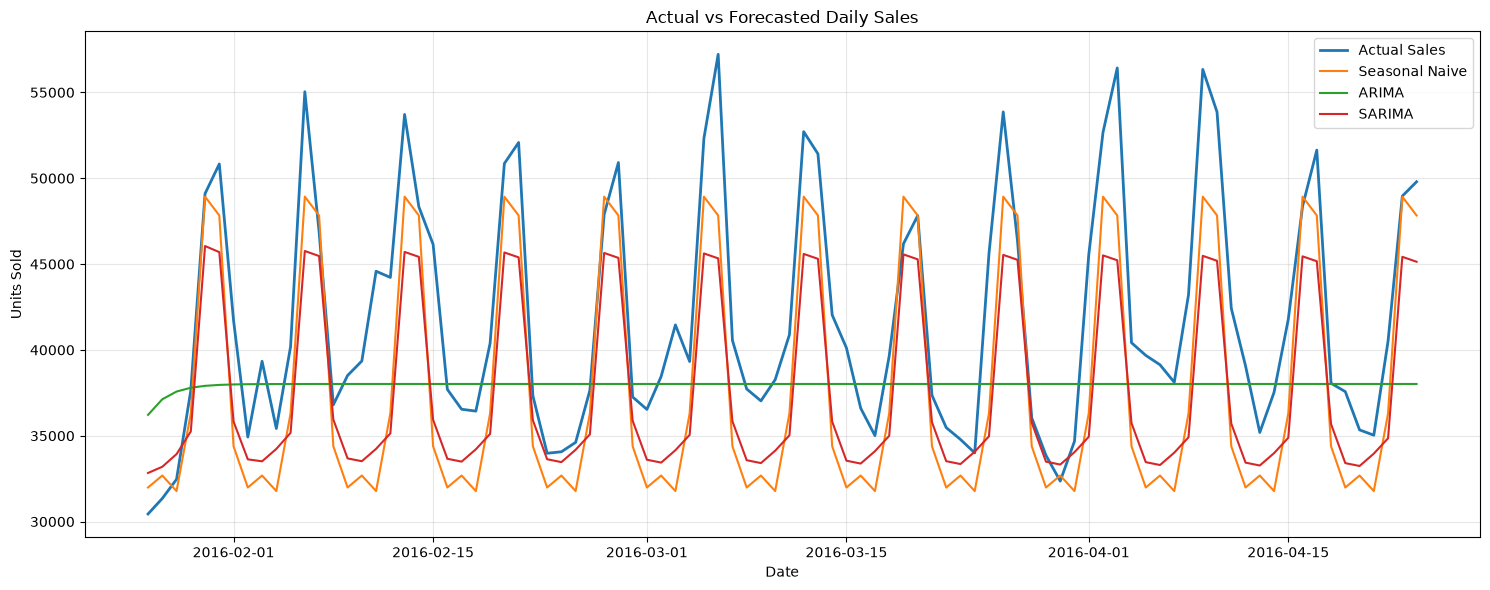

In [17]:
plt.figure(figsize=(15, 6))

plt.plot(test.index, test, label="Actual Sales", linewidth=2)
plt.plot(test.index, baseline_forecast, label="Seasonal Naive")
plt.plot(test.index, arima_forecast, label="ARIMA")
plt.plot(test.index, sarima_forecast, label="SARIMA")

plt.title("Actual vs Forecasted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 15. Forecast Confidence Interval Coverage

In [18]:
lower = sarima_conf_int.iloc[:, 0]
upper = sarima_conf_int.iloc[:, 1]

coverage = (
    (test >= lower) & (test <= upper)
).mean() * 100

print("95% Confidence Interval Coverage:", round(coverage, 2), "%")

95% Confidence Interval Coverage: 97.78 %


### SARIMA Confidence Interval Evaluation

1. The 95% confidence interval achieved an actual coverage of 97.78%.
2. Out of 90 test observations, 88 fell within the predicted confidence intervals.
3. This indicates that the model's prediction intervals captured most of the actual sales values.

Conclusion: SARIMA produced high prediction interval coverage on the test set. However, coverage should be considered along with interval width and forecast accuracy.

# 16. Save forecast results
Let's save all model forecasts and SARIMA confidence intervals for future analysis and dashboard use.

In [19]:
forecast_results = pd.DataFrame({
    "Actual": test,
    "Seasonal_Naive": baseline_forecast,
    "ARIMA": arima_forecast,
    "SARIMA": sarima_forecast,
    "SARIMA_Lower_CI": lower,
    "SARIMA_Upper_CI": upper
})

forecast_results.to_csv(
    PROCESSED_DIR / "arima_sarima_forecasts.csv"
)

print("Forecast results saved successfully!")
print("Shape:", forecast_results.shape)

Forecast results saved successfully!
Shape: (90, 6)


# Save SARIMA model
Let's save the fitted model too, so we can reuse it later without fitting it again.

In [20]:
sarima_result.save(MODELS_DIR / "sarima_model.pkl")

print("SARIMA model saved successfully!")

SARIMA model saved successfully!
